1. Membaca dataset mentah...
2. Membersihkan data transaksi & menu...
3. Menggabungkan tabel (Left Join)...


4. Menghitung ringkasan bisnis...


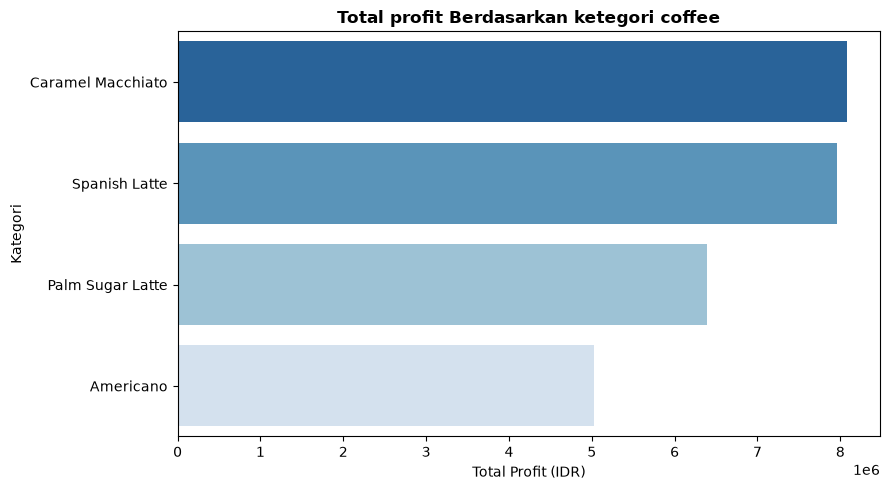

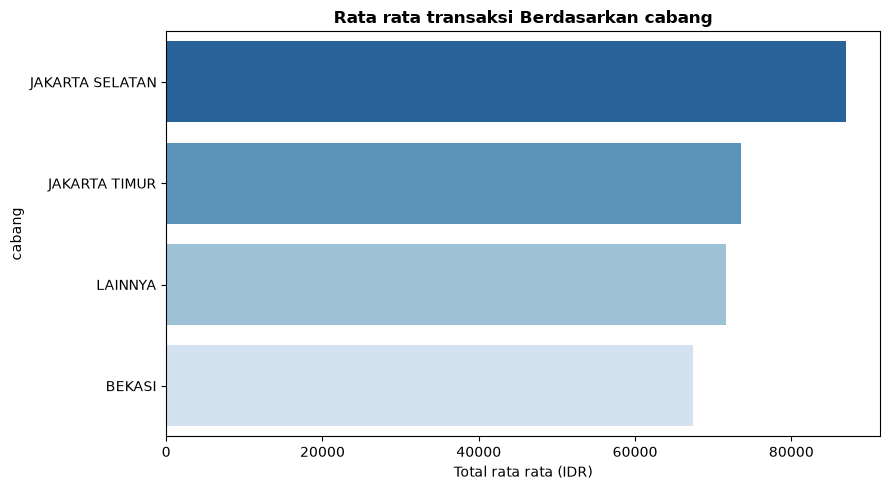

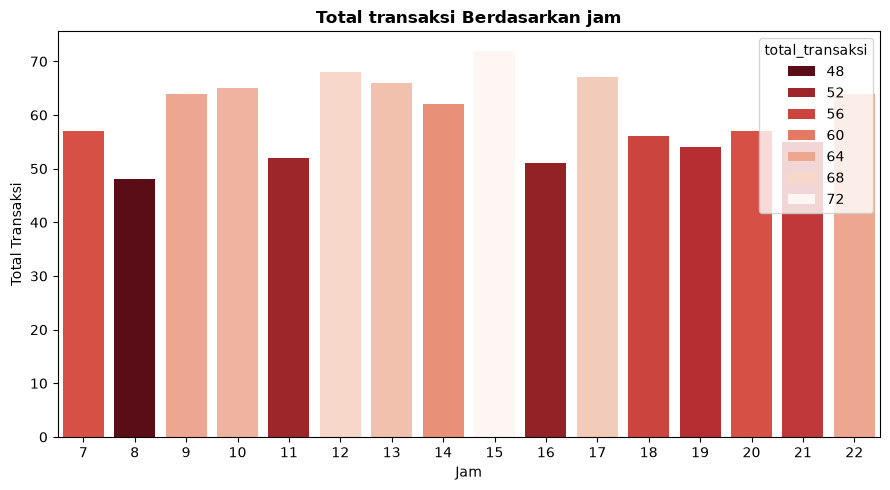

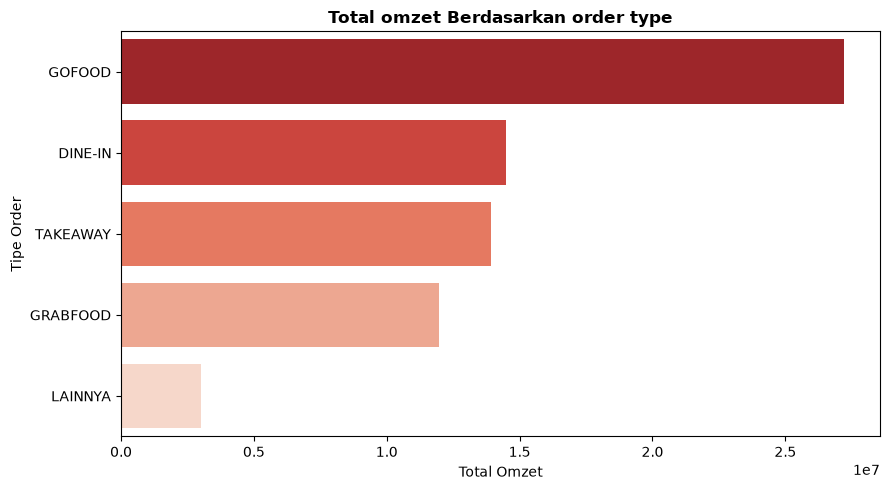

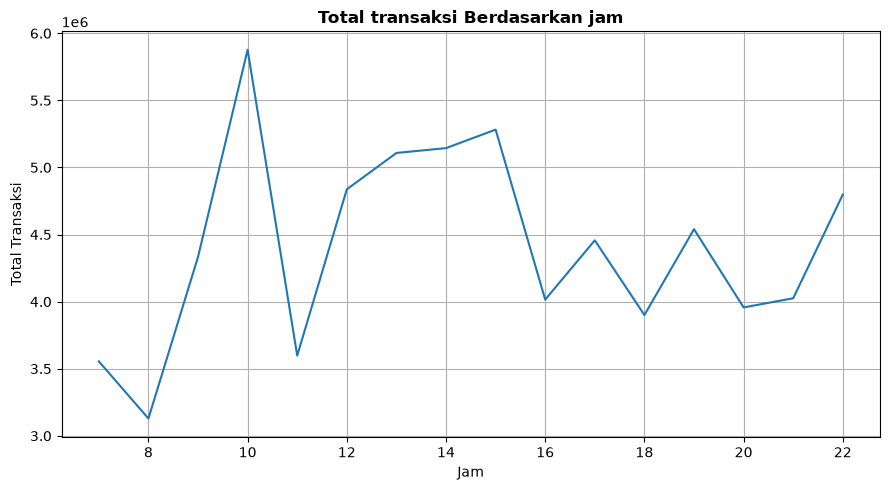

In [34]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def jalankan_pipeline():
    print("1. Membaca dataset mentah...")
    df_menu = pd.read_csv("data/menu_kopi.csv")
    df_trx = pd.read_csv("data/pesanan_kopi.csv")
    
    print("2. Membersihkan data transaksi & menu...")
    # Bersihkan transaksi
    df_trx = df_trx.drop_duplicates(subset=["id_order"]).copy()
    df_trx["waktu_transaksi"] = pd.to_datetime(df_trx["waktu_transaksi"], format="mixed")
    df_trx["tipe_order"] = df_trx["tipe_order"].fillna("Lainnya").str.strip().str.upper()
    df_trx["cabang"] = df_trx["cabang"].fillna("Lainnya").str.strip().str.upper()
    
    print("3. Menggabungkan tabel (Left Join)...")
    df_gabung = pd.merge(df_trx, df_menu, on="id_menu", how="left")
    
    df_gabung["omzet"] = df_gabung["harga_jual"] * df_gabung["qty"]
    df_gabung["profit"] = (df_gabung["harga_jual"] - df_gabung["modal"]) * df_gabung["qty"]
    
    # Ambil hanya transaksi yang sukses selesai
    df_valid = df_gabung[df_gabung["status"] == "Selesai"].copy()
    df_valid["jam"] = df_gabung["waktu_transaksi"].dt.hour
    df_coffee = df_gabung[df_gabung["kategori"] == "Coffee"].copy()
    
    
    print("4. Menghitung ringkasan bisnis...")
    ringkasan_coffee = (
        df_coffee.groupby("nama_menu")
        .agg(
            total_profit=("profit", "sum")
        )
        .sort_values("total_profit", ascending=False)
        .reset_index()
    )
    
    plt.figure(figsize=(9, 5))
    sns.barplot(data=ringkasan_coffee, x="total_profit", y="nama_menu", hue="nama_menu", palette="Blues_r")
    plt.title("Total profit Berdasarkan ketegori coffee", fontweight="bold")
    plt.xlabel("Total Profit (IDR)")
    plt.ylabel("Kategori")
    plt.tight_layout()
    plt.show()
    
    ringkasan_cabang = (
        df_valid.groupby("cabang")
        .agg(
            mean_transaksi=("omzet", "mean")
        )
        .sort_values("mean_transaksi", ascending=False)
        .reset_index()
    )
    
    plt.figure(figsize=(9, 5))
    sns.barplot(data=ringkasan_cabang, x="mean_transaksi", y="cabang", hue="cabang", palette="Blues_r")
    plt.title("Rata rata transaksi Berdasarkan cabang", fontweight="bold")
    plt.xlabel("Total rata rata (IDR)")
    plt.ylabel("cabang")
    plt.tight_layout()
    plt.show()
    
    ringkasan_peak_hours = (
        df_valid.groupby("jam")
        .agg(
            total_transaksi=("id_order", "count")
        )
        .sort_values("total_transaksi", ascending=False)
        .reset_index()
    )
    
    plt.figure(figsize=(9, 5))
    sns.barplot(data=ringkasan_peak_hours, x="jam", y="total_transaksi", hue="total_transaksi", palette="Reds_r")
    plt.title("Total transaksi Berdasarkan jam", fontweight="bold")
    plt.xlabel("Jam")
    plt.ylabel("Total Transaksi")
    plt.tight_layout()
    plt.show()
    
    ringkasan_omzet = (
        df_valid.groupby("tipe_order")
        .agg(
            total_omzet =("omzet", "sum")
        )
        .sort_values("total_omzet", ascending=False)
        .reset_index()
    )
    
    plt.figure(figsize=(9, 5))
    sns.barplot(data=ringkasan_omzet, x="total_omzet", y="tipe_order", hue="tipe_order", palette="Reds_r")
    plt.title("Total omzet Berdasarkan order type", fontweight="bold")
    plt.xlabel("Total Omzet")
    plt.ylabel("Tipe Order")
    plt.tight_layout()
    plt.show()
    
    ringkasan_tren_transaksi = (
        df_valid.groupby("jam")
        .agg(
            total_transaksi=("omzet", "sum")
        )
        .sort_values("jam", ascending=False)
        .reset_index()
    )
    
    x = ringkasan_tren_transaksi["jam"]
    y = ringkasan_tren_transaksi["total_transaksi"]
    
    plt.figure(figsize=(9, 5))
    plt.plot(x,y)
    plt.grid(True)
    plt.title("Total transaksi Berdasarkan jam", fontweight="bold")
    plt.xlabel("Jam")
    plt.ylabel("Total Transaksi")
    plt.tight_layout()
    plt.show()
    
    
jalankan_pipeline()